<a href="https://colab.research.google.com/github/avtonomov-petr/geometry-of-narrative-overfitting/blob/main/narrative_overfitting_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

📊 CASE STUDY 1: Парламентский фракционизм (SVD)
  - Дисперсия оси 1: 54.40% | Дисперсия оси 2: 18.11%
  - Плато шума сингулярных чисел: σ3 = 10.17, σ4 = 9.41
  - Коэффициент детерминации подковы Гуттмана (R²): 0.5580



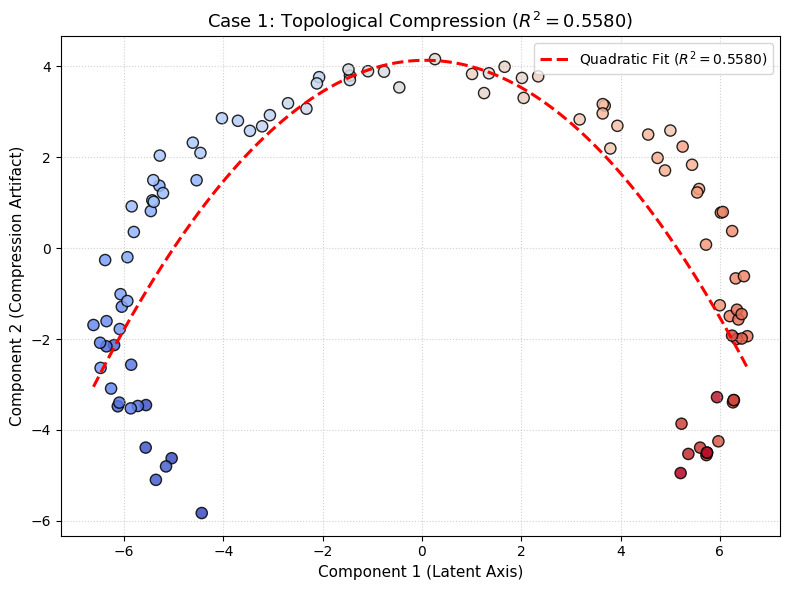

📊 CASE STUDY 2: Макроэкономика и регуляризация Тихонова
  - Число обусловленности Гессиана κ(H): 8.00e+04
  - Эффективные степени свободы (DoF): 7.32 / 150
  - Подавлено эмпирической информации: 95.12%



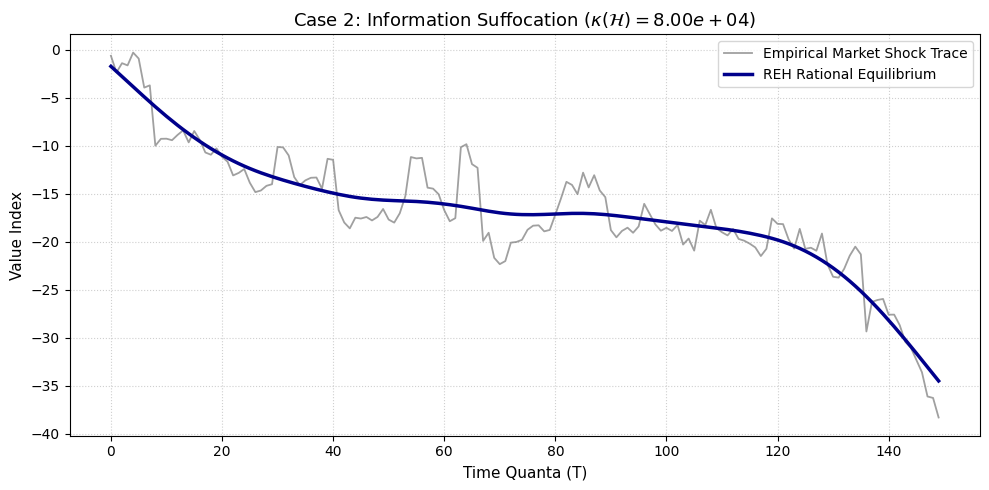

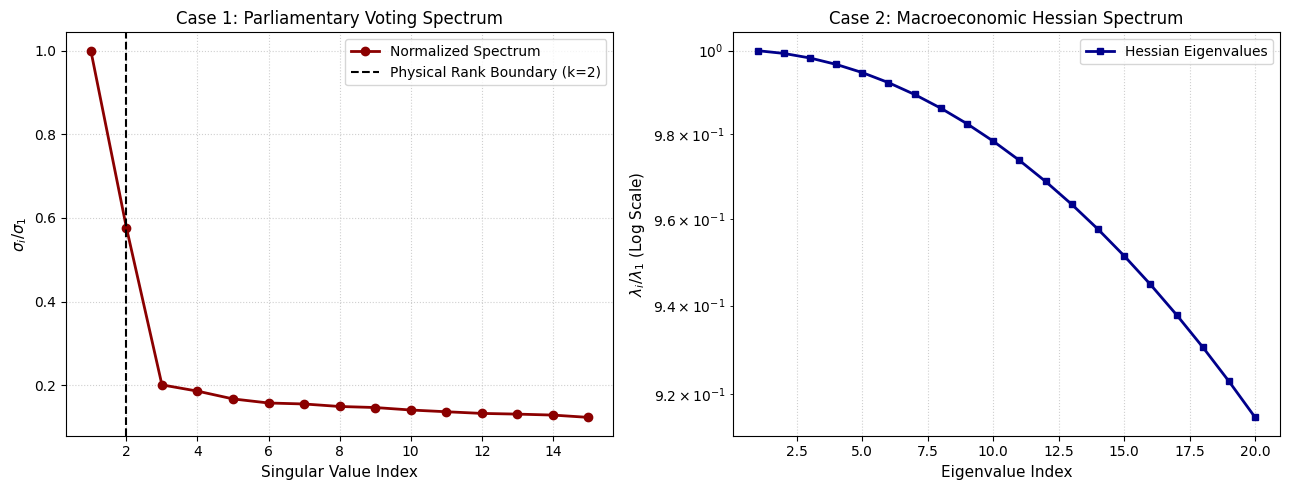

✅ Все расчеты завершены, графики сохранены в высоком разрешении (300 DPI)!


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd

np.random.seed(42)

# =====================================================================
# CASE STUDY 1: ПАРЛАМЕНТСКОЕ ГОЛОСОВАНИЕ И ЭФФЕКТ ПОДКОВЫ ГУТТМАНА
# =====================================================================
N_legislators = 100
M_bills = 50

ideology = np.linspace(-1, 1, N_legislators)
bill_positions = np.linspace(-0.9, 0.9, M_bills)

X_votes = np.zeros((N_legislators, M_bills))
for i in range(N_legislators):
    for j in range(M_bills):
        prob = np.exp(-1.6 * (ideology[i] - bill_positions[j])**2)
        noise = np.random.normal(0, 0.16)
        X_votes[i, j] = 1.0 if (prob + noise) > 0.5 else -1.0

X_centered = X_votes - np.mean(X_votes, axis=0)
U, S, Vt = svd(X_centered, full_matrices=False)
variance_explained = (S**2) / np.sum(S**2) * 100

Z1 = U[:, 0] * S[0]
Z2 = U[:, 1] * S[1]

poly_coeffs = np.polyfit(Z1, Z2, 2)
Z2_pred = np.polyval(poly_coeffs, Z1)
r_squared = 1 - (np.sum((Z2 - Z2_pred)**2) / np.sum((Z2 - np.mean(Z2))**2))

print("📊 CASE STUDY 1: Парламентский фракционизм (SVD)")
print(f"  - Дисперсия оси 1: {variance_explained[0]:.2f}% | Дисперсия оси 2: {variance_explained[1]:.2f}%")
print(f"  - Плато шума сингулярных чисел: σ3 = {S[2]:.2f}, σ4 = {S[3]:.2f}")
print(f"  - Коэффициент детерминации подковы Гуттмана (R²): {r_squared:.4f}\n")

plt.figure(figsize=(8, 6))
plt.scatter(Z1, Z2, c=ideology, cmap='coolwarm', edgecolor='black', s=65, alpha=0.85)
z1_grid = np.linspace(np.min(Z1), np.max(Z1), 200)
plt.plot(z1_grid, np.polyval(poly_coeffs, z1_grid), 'r--', linewidth=2.2, label=f'Quadratic Fit ($R^2 = {r_squared:.4f}$)')
plt.title(f"Case 1: Topological Compression ($R^2 = {r_squared:.4f}$)", fontsize=13)
plt.xlabel("Component 1 (Latent Axis)", fontsize=11)
plt.ylabel("Component 2 (Compression Artifact)", fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('figure_1_horseshoe.png', dpi=300)
plt.show()


# =====================================================================
# CASE STUDY 2: МАКРОЭКОНОМИЧЕСКИЕ ОЖИДАНИЯ И УДУШЕНИЕ ТИХОНОВА
# =====================================================================
T = 150
shocks = np.random.standard_t(df=3, size=T)
y_market = np.cumsum(shocks)

D = np.zeros((T - 2, T))
for i in range(T - 2):
    D[i, i] = 1
    D[i, i + 1] = -2
    D[i, i + 2] = 1

alpha = 5000.0
I_T = np.eye(T)

M_inv = np.linalg.inv(I_T + alpha * D.T @ D)
x_reh = M_inv @ y_market
H_hessian = 2 * (I_T + alpha * D.T @ D)

eigenvalues = np.linalg.eigvalsh(H_hessian)
eigenvalues_desc = eigenvalues[::-1]
cond_number = eigenvalues_desc[0] / eigenvalues_desc[-1]
dof = np.trace(M_inv)

print("📊 CASE STUDY 2: Макроэкономика и регуляризация Тихонова")
print(f"  - Число обусловленности Гессиана κ(H): {cond_number:.2e}")
print(f"  - Эффективные степени свободы (DoF): {dof:.2f} / {T}")
print(f"  - Подавлено эмпирической информации: {((T - dof) / T * 100):.2f}%\n")

# Построение Figure 2
plt.figure(figsize=(10, 5))
plt.plot(y_market, color='gray', alpha=0.75, linewidth=1.3, label='Empirical Market Shock Trace')
plt.plot(x_reh, color='darkblue', linewidth=2.5, label='REH Rational Equilibrium')
plt.title(f"Case 2: Information Suffocation ($\\kappa(\\mathcal{{H}}) = {cond_number:.2e}$)", fontsize=13)
plt.xlabel("Time Quanta (T)", fontsize=11)
plt.ylabel("Value Index", fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('figure_2_suffocation.png', dpi=300)
plt.show()

# =====================================================================
# СИНТЕЗ: НОРМАЛИЗОВАННЫЕ СПЕКТРАЛЬНЫЕ ПРОФИЛИ (FIGURE 3)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

norm_S = S[:15] / S[0]
ax1.plot(np.arange(1, 16), norm_S, 'o-', color='darkred', linewidth=2, markersize=6, label='Normalized Spectrum')
ax1.axvline(x=2, color='black', linestyle='--', linewidth=1.5, label='Physical Rank Boundary (k=2)')
ax1.set_title("Case 1: Parliamentary Voting Spectrum", fontsize=12)
ax1.set_xlabel("Singular Value Index", fontsize=11)
ax1.set_ylabel("$\\sigma_i / \\sigma_1$", fontsize=11)
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

norm_eig = eigenvalues_desc[:20] / eigenvalues_desc[0]
ax2.plot(np.arange(1, 21), norm_eig, 's-', color='darkblue', linewidth=2, markersize=5, label='Hessian Eigenvalues')
ax2.set_yscale('log')
ax2.set_title("Case 2: Macroeconomic Hessian Spectrum", fontsize=12)
ax2.set_xlabel("Eigenvalue Index", fontsize=11)
ax2.set_ylabel("$\\lambda_i / \\lambda_1$ (Log Scale)", fontsize=11)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figure_3_spectra.png', dpi=300)
plt.show()

print("✅ Все расчеты завершены, графики сохранены в высоком разрешении (300 DPI)!")

